___

___

In [1]:
# !conda install -c conda-forge wordcloud
# !conda install -c anaconda networkx
# !conda install -c plotly plotly
# !pip install --upgrade googletrans==4.0.0rc1


In [2]:
import os
import tweepy as tw
import pandas as pd

# Para visualizar los datos
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import networkx as nx
import plotly.express as px

# Para procesar el texto
import nltk
from nltk import bigrams
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, LancasterStemmer, SnowballStemmer
from nltk.stem import WordNetLemmatizer
from nltk.sentiment.vader import SentimentIntensityAnalyzer
import re
import string
import itertools
import collections
from googletrans import Translator

# Para vectorizar el texto
from sklearn.feature_extraction.text import CountVectorizer



Bad key savefig.frameon in file /opt/anaconda3/envs/curso_nlp/lib/python3.7/site-packages/matplotlib/mpl-data/stylelib/_classic_test.mplstyle, line 421 ('savefig.frameon : True')
You probably need to get an updated matplotlibrc file from
https://github.com/matplotlib/matplotlib/blob/v3.3.2/matplotlibrc.template
or from the matplotlib source distribution

Bad key verbose.level in file /opt/anaconda3/envs/curso_nlp/lib/python3.7/site-packages/matplotlib/mpl-data/stylelib/_classic_test.mplstyle, line 472 ('verbose.level  : silent      # one of silent, helpful, debug, debug-annoying')
You probably need to get an updated matplotlibrc file from
https://github.com/matplotlib/matplotlib/blob/v3.3.2/matplotlibrc.template
or from the matplotlib source distribution

Bad key verbose.fileo in file /opt/anaconda3/envs/curso_nlp/lib/python3.7/site-packages/matplotlib/mpl-data/stylelib/_classic_test.mplstyle, line 473 ('verbose.fileo  : sys.stdout  # a log filename, sys.stdout or sys.stderr')
You pro


## Twitter API
El api de twitter utiliza OAuth que es un estándar abierto para autorización de acceso.
Ahora se procederá a obtener cuenta para usar la API de Twitter, dirigiéndonos a el siguiente link https://apps.twitter.com/ y seguir las instrucciones en pantalla.

In [3]:
# Credenciales: se leen de variables de entorno (ver .env.example en la raíz del repo)
import os
APP_KEY = os.getenv("TWITTER_API_KEY")
APP_SECRET = os.getenv("TWITTER_API_SECRET")
OAUTH_TOKEN = os.getenv("TWITTER_ACCESS_TOKEN")
OAUTH_TOKEN_SECRET = os.getenv("TWITTER_ACCESS_TOKEN_SECRET")
BEARER_TOKEN = os.getenv("TWITTER_BEARER_TOKEN")

In [4]:
client = tw.Client(bearer_token=BEARER_TOKEN)

# Configuraciones iniciales

## Definir términos de búsqueda
Definimos los términos de busqueda (usar '+' para varios términos). También podemos indicar desde que fecha.

In [5]:
# Parámetros de búsqueda
search_words = "servicios hoteleros"

In [6]:

new_search = f"{search_words}" #lang:es 
new_search

'servicios hoteleros'

Se puede configurar un lenguaje específico y la cantidad de tweets a recoger

In [7]:

tweets = client.search_recent_tweets(new_search, 
                                  tweet_fields=["id", "text", "lang", "geo", "referenced_tweets"], #https://developer.twitter.com/en/docs/twitter-api/data-dictionary/object-model/tweet
                                  max_results=100
                                 )

In [8]:
tweets_list = [[tweet.id, tweet.text] for tweet in tweets.data]
tweets_list[:10]

[[1654562480943775744,
  '@wilsonariasc @petrogustavo No es verdad lo que ud afirma, al turismo lo están acabando las aerolíneas y empresas del turismo que quieren cobrar en Colombia más o igual que si fuéramos Europa, cuando nuestros servicios hoteleros, turísticos y de transporte claramente no dan la talla para esos precios.'],
 [1654554780180594690,
  'RT @EPBaleares: Hoteleros de Playa de Palma critican la falta de banderas azules y de servicios: "Estamos dando una imagen lamentable" http…'],
 [1654554735590928385,
  'RT @mallorcainforma: https://t.co/MCD0q6G4C3: Hoteleros de Playa de Palma critican la falta de banderas azules y de servicios: “Estamos dan…'],
 [1654554656394051584,
  'RT @CronicaBalear_: Denuncian que esta temporada se está viviendo un "total descontento" en Playa de Palma ante la falta de servicios\n http…'],
 [1654529437377896448,
  'RT @CronicaBalear_: Denuncian que esta temporada se está viviendo un "total descontento" en Playa de Palma ante la falta de servici

In [9]:
tweet_df = pd.DataFrame(data=tweets_list, 
                columns=["id","tweet",])
tweet_df.head()

,id,tweet
0,1654562480943775744,@wilsonariasc @petrogustavo No es verdad lo qu...
1,1654554780180594690,RT @EPBaleares: Hoteleros de Playa de Palma cr...
2,1654554735590928385,RT @mallorcainforma: https://t.co/MCD0q6G4C3: ...
3,1654554656394051584,RT @CronicaBalear_: Denuncian que esta tempora...
4,1654529437377896448,RT @CronicaBalear_: Denuncian que esta tempora...


## Análisis basado en frecuencias

In [10]:
def process(txt):
    txt = " ".join(txt.lower().split())
    txt = " ".join(re.sub(r'http\S+', '', txt).split()) #URLs
    txt = " ".join(re.sub(r'@[\w_]+', '', txt).split()) #@-Mención
    txt = " ".join(re.sub(r'\#+[\w_]+[\w\'_\-]*[\w_]+', '', txt).split()) #Hash-tags
    return  txt.translate(str.maketrans("","",string.punctuation))

In [11]:
def top_n_words(lista, n=None, grafico=True, titulo='Título'):
    vec = CountVectorizer().fit(lista)
    bag_of_words = vec.transform(lista)
    sum_words = bag_of_words.sum(axis=0) 
    words_freq = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
    words_freq =sorted(words_freq, key = lambda x: x[1], reverse=True)
    df2 = pd.DataFrame(words_freq, columns = ['texto' , 'cantidad'])
    df2['%'] = df2['cantidad']/len(lista)*100
    if grafico:
        fig = px.bar(df2.head(n), x='texto', y='cantidad',
                     title='{}'.format(titulo),
                     labels={'texto':'Palabras','y':'cantidad'},
                     color='cantidad')
        fig.show()
    return df2.head(n)

In [12]:
def sentimiento(lista, titulo=''):
    df2 = pd.DataFrame({'sentimiento':lista})
    df2 = df2[df2.sentimiento != 0]
    fig = px.histogram(df2, x='sentimiento',
                       histnorm='', #Puede ser 'percent'
                       title='Distribución de Polaridad - '+ titulo,
                       labels={'sentimiento':titulo,'y':'Porcentaje'},
                       marginal="violin") # puede ser `rug`, `box`)
    fig.show()

In [13]:
def top_n_bigramas(lista, n=None, grafico=True, titulo='Título'):
    vec = CountVectorizer(ngram_range=(2, 2)).fit(lista)
    bag_of_words = vec.transform(lista)
    sum_words = bag_of_words.sum(axis=0) 
    words_freq = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
    words_freq =sorted(words_freq, key = lambda x: x[1], reverse=True)
    df2 = pd.DataFrame(words_freq, columns = ['texto' , 'cantidad'])
    df2['%'] = df2['cantidad']/len(lista)*100
    if grafico:
        fig = px.bar(df2.head(n), x='texto', y='cantidad',
                     title='Bigramas – {}'.format(titulo),
                     labels={'texto':'Palabras','y':'cantidad'},
                     color='cantidad')
        fig.show()
    return df2.head(n)

## Limpieza de los tweets

In [14]:
# Eliminamos tweets repetidos
tweet_df.drop_duplicates(subset=['tweet'], inplace=True)

In [15]:
# Empezamos a limpiar un poco el texto
all_tweets_no_urls = [process(tweet) for tweet in tweet_df.tweet]
all_tweets_no_urls[:5]

['no es verdad lo que ud afirma al turismo lo están acabando las aerolíneas y empresas del turismo que quieren cobrar en colombia más o igual que si fuéramos europa cuando nuestros servicios hoteleros turísticos y de transporte claramente no dan la talla para esos precios',
 'rt  hoteleros de playa de palma critican la falta de banderas azules y de servicios estamos dando una imagen lamentable',
 'rt  hoteleros de playa de palma critican la falta de banderas azules y de servicios “estamos dan…',
 'rt  denuncian que esta temporada se está viviendo un total descontento en playa de palma ante la falta de servicios',
 'hoteleros de playa de palma critican la falta de banderas azules y de servicios']

Divide las palabras de un tweet en tokens (nótese que no se eliminaron puntuaciones)

In [16]:
all_tweets_no_urls[0].split()
words_in_tweet = [tweet.lower().split() for tweet in all_tweets_no_urls]
words_in_tweet[0]

['no',
 'es',
 'verdad',
 'lo',
 'que',
 'ud',
 'afirma',
 'al',
 'turismo',
 'lo',
 'están',
 'acabando',
 'las',
 'aerolíneas',
 'y',
 'empresas',
 'del',
 'turismo',
 'que',
 'quieren',
 'cobrar',
 'en',
 'colombia',
 'más',
 'o',
 'igual',
 'que',
 'si',
 'fuéramos',
 'europa',
 'cuando',
 'nuestros',
 'servicios',
 'hoteleros',
 'turísticos',
 'y',
 'de',
 'transporte',
 'claramente',
 'no',
 'dan',
 'la',
 'talla',
 'para',
 'esos',
 'precios']

Lista de todas las palabras en tweets

In [17]:
all_words_no_urls = list(itertools.chain(*words_in_tweet))

# Crea contador
counts_no_urls = collections.Counter(all_words_no_urls)

#counts_no_urls.most_common(15)
clean_tweets_no_urls = pd.DataFrame(counts_no_urls.most_common(15),
                             columns=['palabras', 'cantidad'])

clean_tweets_no_urls.head(10)

,palabras,cantidad
0,de,41
1,servicios,17
2,hoteleros,17
3,y,16
4,la,13
5,los,12
6,en,10
7,a,9
8,rt,7
9,playa,7


In [18]:
top_n_words(all_tweets_no_urls, n=10, grafico=True, titulo='Palabras comunes que se encuentran en los tweets (incluidas todas las palabras)')

,texto,cantidad,%
0,de,42,233.333333
1,servicios,17,94.444444
2,hoteleros,17,94.444444
3,la,13,72.222222
4,los,12,66.666667
5,en,10,55.555556
6,rt,7,38.888889
7,playa,7,38.888889
8,palma,7,38.888889
9,falta,7,38.888889


## Remover stopwords

In [19]:
stop_words = set(stopwords.words('spanish'))

# Ver algunas palabras del conjunto
list(stop_words)[0:10]

['tanto',
 'tuviésemos',
 'era',
 'las',
 'fueses',
 'habríamos',
 'tuvisteis',
 'tú',
 'estaba',
 'seré']

In [20]:
words_in_tweet[0]

['no',
 'es',
 'verdad',
 'lo',
 'que',
 'ud',
 'afirma',
 'al',
 'turismo',
 'lo',
 'están',
 'acabando',
 'las',
 'aerolíneas',
 'y',
 'empresas',
 'del',
 'turismo',
 'que',
 'quieren',
 'cobrar',
 'en',
 'colombia',
 'más',
 'o',
 'igual',
 'que',
 'si',
 'fuéramos',
 'europa',
 'cuando',
 'nuestros',
 'servicios',
 'hoteleros',
 'turísticos',
 'y',
 'de',
 'transporte',
 'claramente',
 'no',
 'dan',
 'la',
 'talla',
 'para',
 'esos',
 'precios']

Elimina las palabras vacías de cada lista de tweets de palabras

In [21]:
tweets_nsw = [[word for word in tweet_words if not word in stop_words and len(word)>2]
              for tweet_words in words_in_tweet]

tweets_nsw[0]

['verdad',
 'afirma',
 'turismo',
 'acabando',
 'aerolíneas',
 'empresas',
 'turismo',
 'quieren',
 'cobrar',
 'colombia',
 'igual',
 'europa',
 'servicios',
 'hoteleros',
 'turísticos',
 'transporte',
 'claramente',
 'dan',
 'talla',
 'precios']

In [22]:
# Volvemos a revisar el grafico sin stopwords
tweets_ss = [' '.join(tweet_ss) for tweet_ss in tweets_nsw]
top_n_words(tweets_ss, n=10, grafico=True, titulo='Palabras comunes en tweets (sin stopwords)')

,texto,cantidad,%
0,servicios,17,94.444444
1,hoteleros,17,94.444444
2,playa,7,38.888889
3,palma,7,38.888889
4,falta,7,38.888889
5,critican,5,27.777778
6,banderas,5,27.777778
7,azules,5,27.777778
8,turismo,3,16.666667
9,quieren,3,16.666667


In [23]:
collection_words = ['rt', 'servicios', 'hoteleros']

In [24]:
tweets_nsw_nc = [[w for w in word if not w in collection_words]
                 for word in tweets_nsw]

In [25]:
tweets_ss_nc = [' '.join(tweet_ssc) for tweet_ssc in tweets_nsw_nc]
top_n_words(tweets_ss_nc, n=10, grafico=True, titulo='Palabras comunes en tweets (sin stopwords o custom_dict.)')

,texto,cantidad,%
0,playa,7,38.888889
1,palma,7,38.888889
2,falta,7,38.888889
3,critican,5,27.777778
4,banderas,5,27.777778
5,azules,5,27.777778
6,turismo,3,16.666667
7,quieren,3,16.666667
8,dando,3,16.666667
9,imagen,3,16.666667


## Explorar palabras concurrentes (bigramas)

Crear lista de listas que contienen bigrams en tweets

In [26]:
terms_bigram = [bigrams(tweet) for tweet in tweets_nsw_nc]

# Ver bigrams para el primer tweet
terms_bigram[0]

<generator object bigrams at 0x7ff0e1783950>

In [27]:
tweets_list[0]

[1654562480943775744,
 '@wilsonariasc @petrogustavo No es verdad lo que ud afirma, al turismo lo están acabando las aerolíneas y empresas del turismo que quieren cobrar en Colombia más o igual que si fuéramos Europa, cuando nuestros servicios hoteleros, turísticos y de transporte claramente no dan la talla para esos precios.']

Aplanar lista de bigrams en tweets limpios

In [28]:
bigrams = list(itertools.chain(*terms_bigram))

# Crear contador de palabras en bigramas limpios
bigram_counts = collections.Counter(bigrams)

#bigram_counts.most_common(20)
bigram_df = pd.DataFrame(bigram_counts.most_common(20),
                             columns=['bigram', 'count'])

bigram_df.head()

,bigram,count
0,"(playa, palma)",7
1,"(palma, critican)",5
2,"(critican, falta)",5
3,"(falta, banderas)",5
4,"(banderas, azules)",5


In [29]:
tweets_ss_nc = [' '.join(tweet_ssc) for tweet_ssc in tweets_nsw_nc]
top_n_bigramas(tweets_ss_nc, n=10, grafico=True, titulo='Palabras comunes en tweets (sin stopwords o custom_dict.)')

,texto,cantidad,%
0,playa palma,7,38.888889
1,palma critican,5,27.777778
2,critican falta,5,27.777778
3,falta banderas,5,27.777778
4,banderas azules,5,27.777778
5,dando imagen,3,16.666667
6,imagen lamentable,3,16.666667
7,azules dando,2,11.111111
8,azules estamos,2,11.111111
9,denuncian temporada,2,11.111111


## Visualizar redes de Bigrams

Crea un diccionario de bigramas y sus recuentos.

In [30]:
d = bigram_df.set_index('bigram').T.to_dict('records')

## Crear diagrama de red

In [31]:
G = nx.Graph()

# Crea conexiones entre nodos
for k, v in d[0].items():
    G.add_edge(k[0], k[1], weight=(v * 10))


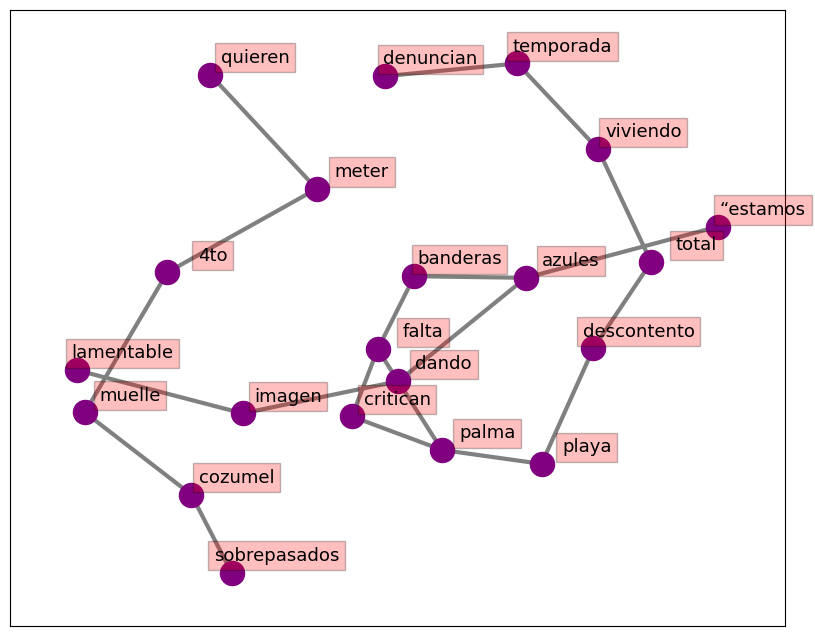

In [32]:
fig, ax = plt.subplots(figsize=(10, 8))

pos = nx.spring_layout(G, k=2)

# Plot networks
nx.draw_networkx(G, pos,
                 font_size=16,
                 width=3,
                 edge_color='grey',
                 node_color='purple',
                 with_labels = False,
                 ax=ax)

# Crea etiquetas
for key, value in pos.items():
    x, y = value[0]+.135, value[1]+.045
    ax.text(x, y,
            s=key,
            bbox=dict(facecolor='red', alpha=0.25),
            horizontalalignment='center', fontsize=13)
    
plt.show()

## Bonus: Nube de palabras

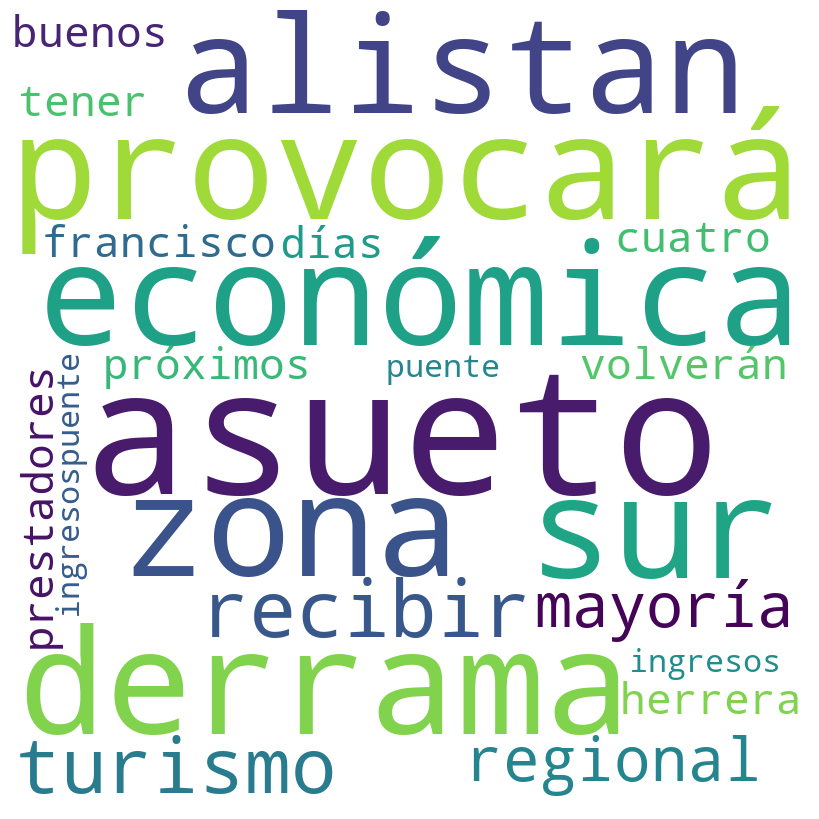

In [33]:
# Nube de palabras
for Palabras in tweets_ss_nc:
    Palabras += str(Palabras+' ')
    
wordcloud = WordCloud(width = 800, height = 800, 
                background_color ='white', #'black', 
                max_words=100,
                min_font_size = 10).generate(Palabras) 
plt.figure(figsize = (8, 8), facecolor = None) 
plt.imshow(wordcloud)#, interpolation="bilinear") 
plt.axis("off") 
plt.tight_layout(pad = 0) 
  
plt.show()

## Modelo pre entrenado

In [34]:
sid = SentimentIntensityAnalyzer()
translator = Translator() # Traductor de Google

In [35]:
tweets = [' '.join(word) for word in words_in_tweet]
tweet_df = pd.DataFrame(data=tweets, 
                columns=["tweet",])
tweet_df.head()

,tweet
0,no es verdad lo que ud afirma al turismo lo es...
1,rt hoteleros de playa de palma critican la fal...
2,rt hoteleros de playa de palma critican la fal...
3,rt denuncian que esta temporada se está vivien...
4,hoteleros de playa de palma critican la falta ...


In [47]:
tweet_df['translation'] = tweet_df['tweet'].apply(lambda x: translator.translate(x, dest='en').text)
tweet_df['score'] = tweet_df['translation'].apply(lambda x: sid.polarity_scores(x)["compound"])
tweet_df['sentimiento'] = tweet_df['score'].apply(lambda x: 'pos' if x >=0 else 'neg')
tweet_df.drop(columns=['translation'], inplace=True)
tweet_df.head()


,tweet,score,sentimiento
0,no es verdad lo que ud afirma al turismo lo es...,0.5317,pos
1,rt hoteleros de playa de palma critican la fal...,-0.6705,neg
2,rt hoteleros de playa de palma critican la fal...,-0.5994,neg
3,rt denuncian que esta temporada se está vivien...,-0.4404,neg
4,hoteleros de playa de palma critican la falta ...,-0.5994,neg


/opt/anaconda3/envs/curso_nlp/lib/python3.7/site-packages/seaborn/_decorators.py:43: FutureWarning:

Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.



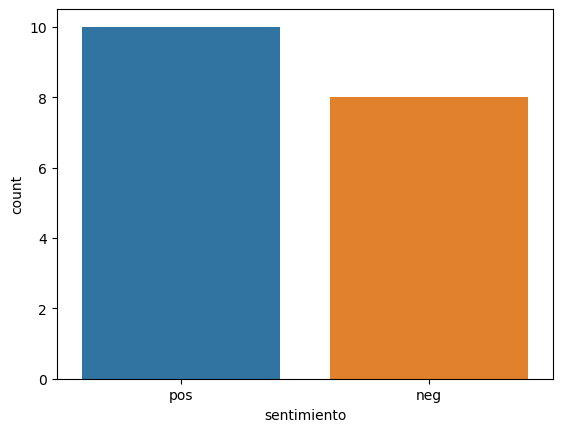

In [52]:
sns.countplot(tweet_df.sentimiento)
plt.show()